# Clasificación de ingresos anuales con Spark MLlib

**Pontificia Universidad Javeriana**  
Ingeniería de Sistemas · Procesamiento de Datos a Gran Escala  
**Estudiante** Andrés Felipe Díaz Torres  
**Profesor** John Corredor  
**Fecha de entrega** 24 de noviembre de 2026

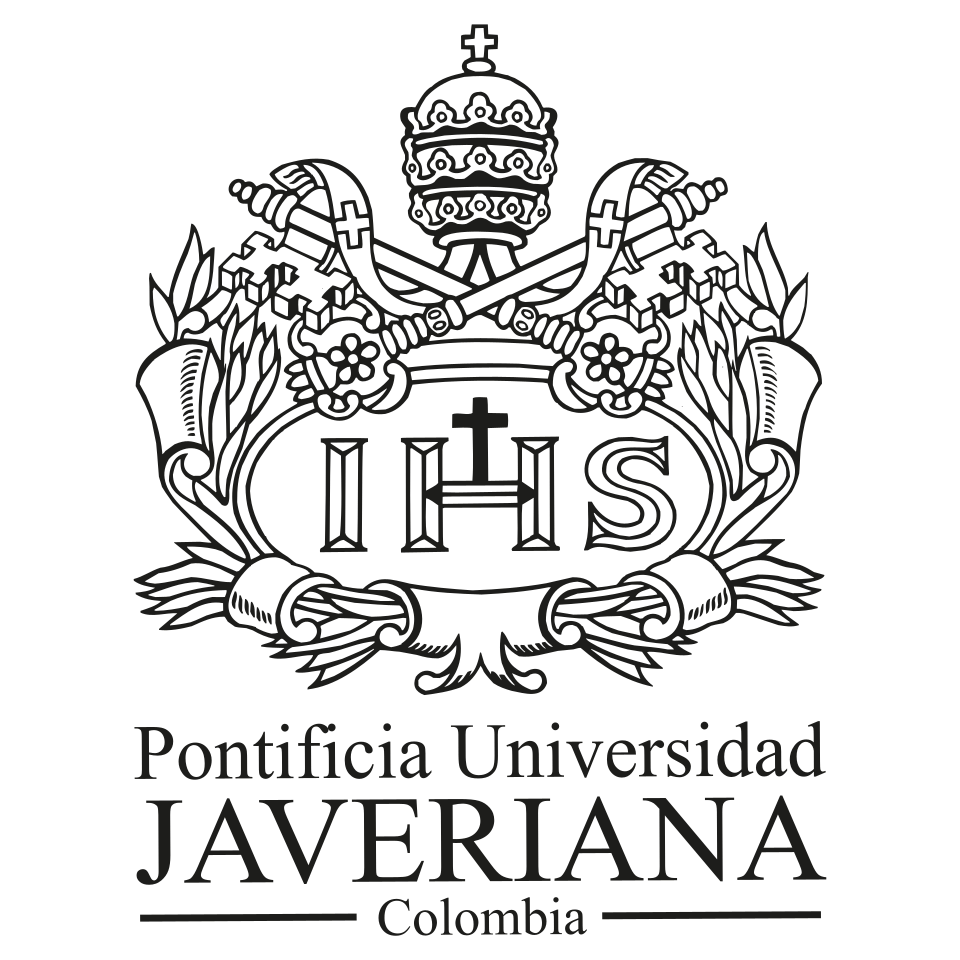

## Contexto

¿Con qué frecuencia se puede identificar a quienes superan los USD 50.000 de ingreso anual a partir de sus datos censales? Becker extrajo los registros de una base censal de Estados Unidos de 1994. La selección incluye personas mayores de 16 años con horas de trabajo registradas. La ficha de UCI reúne 48.842 registros, 14 características y una etiqueta que indica de qué lado del umbral queda cada persona. El censo indica el tramo de ingreso anual de cada persona. El reto es detectar a quienes superan el umbral, el grupo menos frecuente de la muestra. [Fuente de los datos y criterios de selección, UCI](https://archive.ics.uci.edu/dataset/20/census+income)

## Objetivo general

Evaluar qué tan bien cinco clasificadores de Spark MLlib identifican a las personas con ingresos anuales superiores a USD 50.000 en la partición oficial de prueba.

## Objetivos específicos

- Describir la edad de los participantes, comparar la proporción que supera el umbral dentro de cada género y examinar las horas de trabajo semanales por nivel de ingreso.
- Identificar qué variables tienen datos faltantes, justificar su tratamiento y comprobar cuántos registros se conservaron en cada partición.
- Preparar los predictores con PySpark a partir de los archivos en HDFS y aplicar a la prueba las transformaciones aprendidas con entrenamiento.
- Comparar los cinco modelos con la misma prueba. Recomendar un modelo según el F1 de la clase superior a USD 50.000 y explicar, con precisión y sensibilidad, cuántas de sus predicciones positivas son correctas y cuántos casos detecta.

## Importación de librerías

In [1]:
# Biblioteca para manejo de tablas
import pandas as pd

# Biblioteca para dibujar las gráficas
import matplotlib.pyplot as plt

# Biblioteca para localizar los archivos de datos
from pathlib import Path

# Biblioteca para ejecutar los comandos de Hadoop
import subprocess

# Biblioteca para localizar Spark en el clúster
import findspark
findspark.init("/mnt/sda1/Cluster/Spark")

In [2]:
# Configuración de Spark
from pyspark import SparkConf

# Creación de la sesión de Spark
from pyspark.sql import SparkSession

# Funciones para trabajar con columnas de los DataFrames
from pyspark.sql import functions as F

# Clasificadores de Spark MLlib
from pyspark.ml.classification import (
    DecisionTreeClassifier, LogisticRegression, MultilayerPerceptronClassifier,
    NaiveBayes, RandomForestClassifier
)

# Evaluador de clasificación binaria
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Transformaciones para preparar las variables y construir los vectores
from pyspark.ml.feature import (
    OneHotEncoder, QuantileDiscretizer, StandardScaler, StringIndexer, VectorAssembler
)

# Tuberías para encadenar las transformaciones
from pyspark.ml import Pipeline

## Creación de la sesión de Spark

In [3]:
# Se configura el nombre del taller y el puerto de la sesión
configura = SparkConf().setAppName("DiazSalario_1055")
configura.set("spark.ui.port", "37007")

# Se crea la sesión y se consulta la versión de Spark
spark = SparkSession.builder.config(conf=configura).getOrCreate()
print(f"Spark {spark.version} | modo {spark.sparkContext.master}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.5 | modo spark://10.195.34.34:7077


## Carga de datos

Los archivos **adult.data** y **adult.test** vienen separados por comas y sin encabezado. Se conservan las particiones de entrenamiento y prueba de UCI.

In [4]:
# Se define la carpeta del taller en Hadoop HDFS
HADOOP = "/mnt/sda1/Cluster/Hadoop/bin/hadoop"
RUTA_HDFS = "hdfs://10.195.34.34:9000/Formatos1055/DiazTorres/Salarios"
archivos = ("adult.data", "adult.test")


def hadoop(*args, verificar=True):
    resultado = subprocess.run([HADOOP, "fs", *args], capture_output=True, text=True)
    if verificar and resultado.returncode != 0:
        raise RuntimeError(resultado.stderr.strip() or f"Falló Hadoop: {args}")
    return resultado

In [5]:
# Se crea la carpeta en HDFS y se copian los archivos que todavía falten
hadoop("-mkdir", "-p", RUTA_HDFS)
for nombre in archivos:
    destino = f"{RUTA_HDFS}/{nombre}"
    if hadoop("-test", "-e", destino, verificar=False).returncode == 0:
        continue

    ubicaciones = (Path(nombre), Path("census+income") / nombre)
    origen = next((ruta for ruta in ubicaciones if ruta.is_file()), None)
    if origen is None:
        raise FileNotFoundError(f"No se encontró {nombre} junto al cuaderno.")
    hadoop("-put", str(origen.resolve()), destino)

In [6]:
# Se verifica que los dos archivos quedaron en la carpeta de Hadoop
print(hadoop("-ls", RUTA_HDFS).stdout)

Found 2 items
-rw-r--r--   2 usuario07 supergroup    3974305 2026-11-21 18:04 hdfs://10.195.34.34:9000/Formatos1055/DiazTorres/Salarios/adult.data
-rw-r--r--   2 usuario07 supergroup    2003153 2026-11-21 18:04 hdfs://10.195.34.34:9000/Formatos1055/DiazTorres/Salarios/adult.test



In [7]:
# df00 conserva los campos originales como texto.
# Se omite la línea de comentario que trae adult.test.
lector = (spark.read.option("header", "false")
          .option("comment", "|")
          .option("ignoreLeadingWhiteSpace", "true")
          .option("ignoreTrailingWhiteSpace", "true")
          .option("mode", "FAILFAST"))

df00 = lector.csv(f"{RUTA_HDFS}/adult.data")
df00_prueba = lector.csv(f"{RUTA_HDFS}/adult.test")
df00.show(5, truncate=False)

+---+----------------+------+---------+---+------------------+-----------------+-------------+-----+------+----+----+----+-------------+-----+
|_c0|_c1             |_c2   |_c3      |_c4|_c5               |_c6              |_c7          |_c8  |_c9   |_c10|_c11|_c12|_c13         |_c14 |
+---+----------------+------+---------+---+------------------+-----------------+-------------+-----+------+----+----+----+-------------+-----+
|39 |State-gov       |77516 |Bachelors|13 |Never-married     |Adm-clerical     |Not-in-family|White|Male  |2174|0   |40  |United-States|<=50K|
|50 |Self-emp-not-inc|83311 |Bachelors|13 |Married-civ-spouse|Exec-managerial  |Husband      |White|Male  |0   |0   |13  |United-States|<=50K|
|38 |Private         |215646|HS-grad  |9  |Divorced          |Handlers-cleaners|Not-in-family|White|Male  |0   |0   |40  |United-States|<=50K|
|53 |Private         |234721|11th     |7  |Married-civ-spouse|Handlers-cleaners|Husband      |Black|Male  |0   |0   |40  |United-States|<=50K|

## 1. Diagnóstico y tratamiento de datos

Se revisan los nombres de las columnas, los tipos y los valores faltantes antes de preparar los datos.

In [8]:
# Se revisan las columnas y los tipos que Spark encontró al leer
print(df00.columns)
df00.printSchema()

['_c0', '_c1', '_c2', '_c3', '_c4', '_c5', '_c6', '_c7', '_c8', '_c9', '_c10', '_c11', '_c12', '_c13', '_c14']
root
 |-- _c0: string (nullable = true)
 |-- _c1: string (nullable = true)
 |-- _c2: string (nullable = true)
 |-- _c3: string (nullable = true)
 |-- _c4: string (nullable = true)
 |-- _c5: string (nullable = true)
 |-- _c6: string (nullable = true)
 |-- _c7: string (nullable = true)
 |-- _c8: string (nullable = true)
 |-- _c9: string (nullable = true)
 |-- _c10: string (nullable = true)
 |-- _c11: string (nullable = true)
 |-- _c12: string (nullable = true)
 |-- _c13: string (nullable = true)
 |-- _c14: string (nullable = true)



In [9]:
# df01 asigna los nombres del diccionario de UCI en el orden del archivo
columnas = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]
df01 = df00.toDF(*columnas)
df01_prueba = df00_prueba.toDF(*columnas)
print(df01.columns)

['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


In [10]:
# Se revisa la cantidad de datos en cada partición
print(f"Entrenamiento: {df01.count()} registros")
print(f"Prueba: {df01_prueba.count()} registros")

# Se comparan las etiquetas tal como vienen en cada archivo
df01.groupBy("income").count().show()
df01_prueba.groupBy("income").count().show()

Entrenamiento: 32561 registros
Prueba: 16281 registros


+------+-----+
|income|count|
+------+-----+
| <=50K|24720|
|  >50K| 7841|
+------+-----+

+------+-----+
|income|count|
+------+-----+
|<=50K.|12435|
| >50K.| 3846|
+------+-----+



In [11]:
# Identificación de datos faltantes por columna: nulos, vacíos o signos ?
def revisar_faltantes(datos):
    conteos = []
    for columna in datos.columns:
        valor = F.trim(F.col(columna).cast("string"))
        falta = valor.isNull() | valor.isin("", "?")
        conteos.append(F.count(F.when(falta, 1)).alias(columna))
    return datos.select(*conteos)

In [12]:
# Se muestran los conteos de faltantes antes del tratamiento
print("Entrenamiento")
revisar_faltantes(df01).show()
print("Prueba")
revisar_faltantes(df01_prueba).show()

Entrenamiento
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+
|age|workclass|fnlwgt|education|education_num|marital_status|occupation|relationship|race|sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+
|  0|     1836|     0|        0|            0|             0|      1843|           0|   0|  0|           0|           0|             0|           583|     0|
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+

Prueba
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+
|age|workclass|fnlwgt|educatio

Los faltantes se concentran en la ocupación, el tipo de empleo y el país de origen. En entrenamiento aparecen 1.843, 1.836 y 583 veces, respectivamente. En prueba aparecen 966, 963 y 274 veces. Una persona puede aparecer en varios conteos. En las seis variables numéricas, incluida la edad, el conteo de faltantes fue cero.

In [13]:
# df02 cambia las variables numéricas de texto a entero.
# Se retira el punto para usar las mismas etiquetas en ambos archivos.
numericas_originales = [
    "age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"
]


def ajustar_tipos(datos):
    for columna in numericas_originales:
        datos = datos.withColumn(columna, F.col(columna).cast("int"))
    ingreso = F.regexp_replace(F.trim(F.col("income")), r"\.$", "")
    return datos.withColumn("income", ingreso)


df02 = ajustar_tipos(df01)
df02_prueba = ajustar_tipos(df01_prueba)
df02.printSchema()

root
 |-- age: integer (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: integer (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: integer (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: integer (nullable = true)
 |-- capital_loss: integer (nullable = true)
 |-- hours_per_week: integer (nullable = true)
 |-- native_country: string (nullable = true)
 |-- income: string (nullable = true)



In [14]:
# Se revisan las categorías con faltantes y las estadísticas numéricas
for columna in ("workclass", "occupation", "native_country"):
    df02.groupBy(columna).count().orderBy(F.desc("count")).show(5)

df02.select(*numericas_originales).describe().show()

+----------------+-----+
|       workclass|count|
+----------------+-----+
|         Private|22696|
|Self-emp-not-inc| 2541|
|       Local-gov| 2093|
|               ?| 1836|
|       State-gov| 1298|
+----------------+-----+
only showing top 5 rows

+---------------+-----+
|     occupation|count|
+---------------+-----+
| Prof-specialty| 4140|
|   Craft-repair| 4099|
|Exec-managerial| 4066|
|   Adm-clerical| 3770|
|          Sales| 3650|
+---------------+-----+
only showing top 5 rows

+--------------+-----+
|native_country|count|
+--------------+-----+
| United-States|29170|
|        Mexico|  643|
|             ?|  583|
|   Philippines|  198|
|       Germany|  137|
+--------------+-----+
only showing top 5 rows



26/11/23 17:20:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+-----------------+------------------+----------------+------------------+
|summary|               age|            fnlwgt|    education_num|      capital_gain|    capital_loss|    hours_per_week|
+-------+------------------+------------------+-----------------+------------------+----------------+------------------+
|  count|             32561|             32561|            32561|             32561|           32561|             32561|
|   mean| 38.58164675532078|189778.36651208502| 10.0806793403151|1077.6488437087312| 87.303829734959|40.437455852092995|
| stddev|13.640432553581356|105549.97769702227|2.572720332067397| 7385.292084840354|402.960218649002|12.347428681731838|
|    min|                17|             12285|                1|                 0|               0|                 1|
|    max|                90|           1484705|               16|             99999|            4356|                99|
+-------+------------------+----

### ¿Se pueden completar las categorías por grupos?

Para una variable numérica se podría calcular la media o la mediana entre personas de edad similar. Para una ocupación, la alternativa sería la moda, es decir, la respuesta más frecuente. Para ver qué tan representativa sería, se revisan las ocupaciones registradas entre personas de 30 a 39 años que terminaron secundaria.

In [15]:
# Ocupaciones conocidas en un grupo de la misma década de edad y nivel educativo
grupo = df02.filter(F.col("age").between(30, 39) & (F.col("education") == "HS-grad"))
ocupaciones = grupo.filter(
    F.col("occupation").isNotNull() & ~F.trim(F.col("occupation")).isin("", "?"))
total_conocido = ocupaciones.count()
(ocupaciones.groupBy("occupation").count()
 .withColumn("porcentaje", F.round(100 * F.col("count") / total_conocido, 2))
 .orderBy(F.desc("count"), "occupation").show(5, truncate=False))

+-----------------+-----+----------+
|occupation       |count|porcentaje|
+-----------------+-----+----------+
|Craft-repair     |643  |22.5      |
|Other-service    |355  |12.42     |
|Adm-clerical     |346  |12.11     |
|Machine-op-inspct|314  |10.99     |
|Transport-moving |267  |9.34      |
+-----------------+-----+----------+
only showing top 5 rows



Entre las 2.858 personas de ese grupo con ocupación conocida, 643 declararon oficios de producción o reparación (Craft-repair). Incluso dentro de la misma década de edad y nivel educativo, la ocupación más frecuente solo representa el 22,50 % del grupo.

In [16]:
# df03 conserva los faltantes categóricos como Desconocido.
# Se asigna 1 a ingresos >50K y 0 a ingresos <=50K.
categoricas_originales = [columna for columna in columnas
                         if columna not in numericas_originales + ["income"]]


def tratar_faltantes(datos):
    datos = datos.replace({"?": "Desconocido", "": "Desconocido"},
                          subset=categoricas_originales)
    datos = datos.fillna("Desconocido", subset=categoricas_originales)
    etiqueta = F.when(F.col("income") == ">50K", 1.0).when(F.col("income") == "<=50K", 0.0)
    return datos.withColumn("label", etiqueta)


df03 = tratar_faltantes(df02).cache()
df03_prueba = tratar_faltantes(df02_prueba).cache()
df03.show(5, truncate=False)

+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+-----+
|age|workclass       |fnlwgt|education|education_num|marital_status    |occupation       |relationship |race |sex   |capital_gain|capital_loss|hours_per_week|native_country|income|label|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+-----+
|39 |State-gov       |77516 |Bachelors|13           |Never-married     |Adm-clerical     |Not-in-family|White|Male  |2174        |0           |40            |United-States |<=50K |0.0  |
|50 |Self-emp-not-inc|83311 |Bachelors|13           |Married-civ-spouse|Exec-managerial  |Husband      |White|Male  |0           |0           |13            |United-States |<=50K |0.0  |
|38 |Private         |215646|HS-grad  |9            |Divorced    

In [17]:
# Se revisan los faltantes después del tratamiento y se validan las etiquetas
for nombre, datos in (("Entrenamiento", df03), ("Prueba", df03_prueba)):
    print(nombre)
    faltantes = revisar_faltantes(datos)
    faltantes.show()
    if any(faltantes.first()):
        raise ValueError(f"Quedaron campos sin tratar en {nombre}.")
    conteo = datos.groupBy("label").count().collect()
    if {fila["label"] for fila in conteo} != {0.0, 1.0}:
        raise ValueError(f"Etiquetas inválidas o incompletas en {nombre}.")

Entrenamiento
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+-----+
|age|workclass|fnlwgt|education|education_num|marital_status|occupation|relationship|race|sex|capital_gain|capital_loss|hours_per_week|native_country|income|label|
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+-----+
|  0|        0|     0|        0|            0|             0|         0|           0|   0|  0|           0|           0|             0|             0|     0|    0|
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+-----+

Prueba
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+-

In [18]:
# Se cuenta cada persona una sola vez, aunque tenga varios campos desconocidos
campos_faltantes = ["occupation", "workclass", "native_country"]
for nombre, datos in (("Entrenamiento", df03), ("Prueba", df03_prueba)):
    con_desconocido = F.array_contains(F.array(*campos_faltantes), "Desconocido")
    print(f"{nombre}: {datos.filter(con_desconocido).count()} filas con algún dato desconocido de {datos.count()} filas.")

Entrenamiento: 2399 filas con algún dato desconocido de 32561 filas.
Prueba: 1221 filas con algún dato desconocido de 16281 filas.


Aunque falte la ocupación, sí sabemos en qué tramo de ingreso quedó esa persona. Conservamos su registro y marcamos la ocupación como Desconocido, porque asignarle la profesión más frecuente del grupo supondría una respuesta que la persona no dio. Aplicamos el mismo criterio cuando falta el tipo de empleo o el país de origen.

El primer conteo da cero porque ahora todos los campos tienen un valor. El segundo muestra cuántas personas conservan al menos una respuesta desconocida. Son 2.399 en entrenamiento y 1.221 en prueba.

## 2. Análisis exploratorio de los datos

Las gráficas describen los registros de la muestra, sin ponderarlos por su peso censal. Para las gráficas individuales se guardan en pandas las cuatro columnas de entrenamiento que se van a usar. De la prueba solo se toma el conteo por clase para comparar la composición de ambas particiones.

In [19]:
# Datos para las gráficas de entrenamiento y conteos por clase de la prueba
datos_salario = df03.select("age", "sex", "hours_per_week", "income").toPandas()
distribucion_prueba = df03_prueba.groupBy("income").count().toPandas()

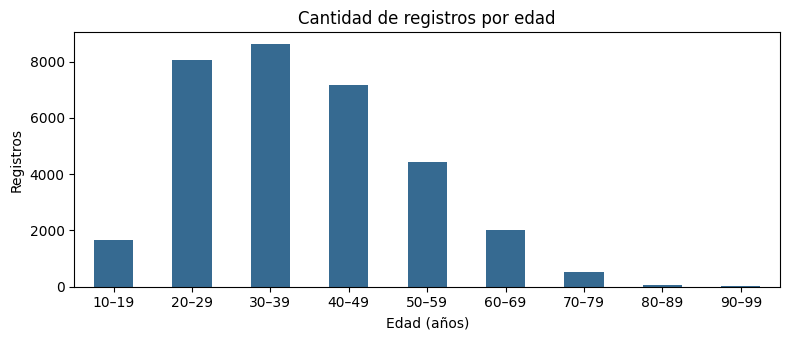

In [20]:
# Cantidad de registros por década en la muestra de entrenamiento
decada = (datos_salario["age"] // 10) * 10
edad = decada.value_counts().sort_index()
edad.index = [f"{inicio}–{inicio + 9}" for inicio in edad.index]

ax = edad.plot.bar(color="#366A91", rot=0, figsize=(8, 3.5))
ax.set(title="Cantidad de registros por edad", xlabel="Edad (años)", ylabel="Registros")
ax.figure.tight_layout()
plt.show()

**Análisis.** Los grupos con más registros son el de 30 a 39 años (8.613) y el de 20 a 29 años (8.054). Entre los 20 y los 49 años se concentra el 73,22 % del conjunto de entrenamiento. Los grupos de mayor edad tienen mucha menos representación.

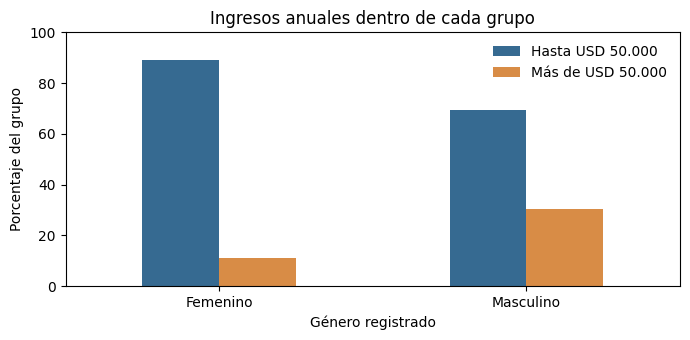

In [21]:
# Proporciones dentro de cada género para comparar grupos de distinto tamaño
tabla_genero = pd.crosstab(datos_salario["sex"], datos_salario["income"], normalize="index") * 100
tabla_genero = tabla_genero.rename(index={"Female": "Femenino", "Male": "Masculino"})

ax = tabla_genero[["<=50K", ">50K"]].plot.bar(rot=0, figsize=(7, 3.5), color=["#366A91", "#D88C46"])
ax.set(title="Ingresos anuales dentro de cada grupo", xlabel="Género registrado",
       ylabel="Porcentaje del grupo", ylim=(0, 100))
ax.legend(["Hasta USD 50.000", "Más de USD 50.000"], frameon=False)
ax.figure.tight_layout()
plt.show()

**Análisis.** En entrenamiento hay 21.790 registros de hombres y 10.771 de mujeres. Dentro de cada grupo, superan los USD 50.000 el 30,57 % de los hombres (6.662 registros) y el 10,95 % de las mujeres (1.179 registros). La diferencia describe estos datos censales y por sí sola no establece sus causas.

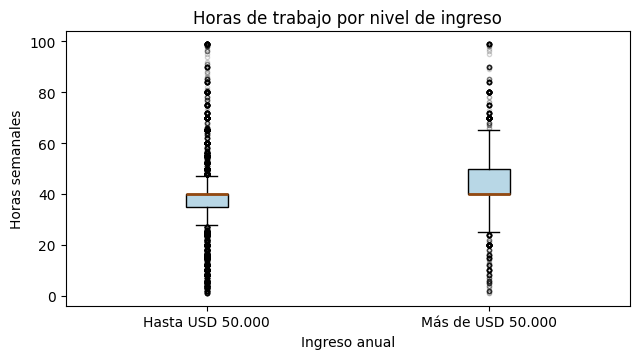

In [22]:
# Distribución de las horas semanales dentro de cada categoría de ingresos
categorias_ingreso = ["<=50K", ">50K"]
horas = [datos_salario.loc[datos_salario["income"] == clase, "hours_per_week"]
         for clase in categorias_ingreso]

fig, ax = plt.subplots(figsize=(6.5, 3.7))
ax.boxplot(horas, patch_artist=True, boxprops={"facecolor": "#B8D7E6"},
           medianprops={"color": "#944A12", "linewidth": 2},
           flierprops={"marker": ".", "alpha": 0.18})
ax.set_xticks([1, 2])
ax.set_xticklabels(["Hasta USD 50.000", "Más de USD 50.000"])
ax.set(title="Horas de trabajo por nivel de ingreso", xlabel="Ingreso anual",
       ylabel="Horas semanales")
fig.tight_layout()
plt.show()

En ambos grupos la mediana es de 40 horas semanales. Lo que cambia es la mitad central de los registros. Va de 35 a 40 horas entre quienes ganan hasta USD 50.000 y de 40 a 50 horas entre quienes superan el umbral. Hay personas con jornadas similares en ambas clases, por lo que las horas por sí solas dan información limitada para clasificar un registro.

income         <=50K  >50K
Entrenamiento  24720  7841
Prueba         12435  3846


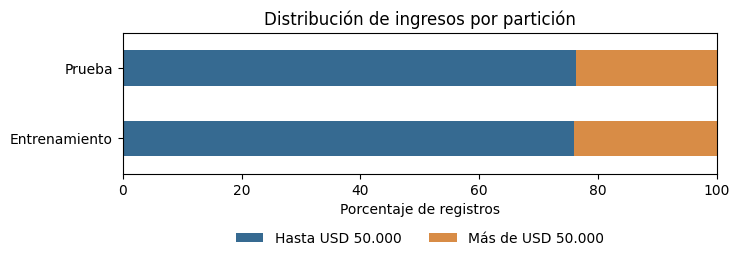

In [23]:
# Distribución de ingresos en las particiones oficiales
entrenamiento = datos_salario["income"].value_counts()
prueba = distribucion_prueba.set_index("income")["count"]
tabla_clases = pd.DataFrame({"Entrenamiento": entrenamiento, "Prueba": prueba}).T
porcentajes = tabla_clases.div(tabla_clases.sum(axis=1), axis=0) * 100
print(tabla_clases.to_string())

ax = porcentajes[["<=50K", ">50K"]].plot.barh(
    stacked=True, color=["#366A91", "#D88C46"], figsize=(7.5, 3))
ax.set(xlim=(0, 100), xlabel="Porcentaje de registros", ylabel="",
       title="Distribución de ingresos por partición")
ax.legend(["Hasta USD 50.000", "Más de USD 50.000"], loc="upper center",
          bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
ax.figure.tight_layout()
plt.show()

**Análisis.** La proporción de ingresos superiores a USD 50.000 es similar en entrenamiento (24,08 %) y prueba (23,62 %). En prueba, clasificar a todos en la categoría de USD 50.000 o menos daría un 76,38 % de exactitud y dejaría sin detectar los 3.846 casos de la clase positiva.

## 3. Preparación de datos para los modelos

La variable a predecir vale 1 cuando el ingreso anual supera los USD 50.000 y 0 en los demás casos. El vector de predictores reúne cinco variables numéricas y los indicadores de cinco categóricas. El nivel educativo ya está representado por su valor numérico. El peso censal, la raza y el género quedan fuera del vector.

In [24]:
# Se separan las variables categóricas y las numéricas que entran al modelo
numericas = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
categoricas = ["workclass", "marital_status", "occupation", "relationship", "native_country"]
indices = [f"{nombre}_idx" for nombre in categoricas]
indicadores = [f"{nombre}_ohe" for nombre in categoricas]

In [25]:
# df04 agrega los índices y los indicadores de las variables categóricas
indexadores = [
    StringIndexer(inputCol=nombre, outputCol=indice, handleInvalid="keep")
    for nombre, indice in zip(categoricas, indices)
]
codificador = OneHotEncoder(inputCols=indices, outputCols=indicadores, dropLast=False)
tuberia_categorias = Pipeline(stages=[*indexadores, codificador]).fit(df03)

df04 = tuberia_categorias.transform(df03)
df04_prueba = tuberia_categorias.transform(df03_prueba)
df04.select("occupation", "occupation_idx", "occupation_ohe").show(5, truncate=False)

+-----------------+--------------+--------------+
|occupation       |occupation_idx|occupation_ohe|
+-----------------+--------------+--------------+
|Adm-clerical     |3.0           |(16,[3],[1.0])|
|Exec-managerial  |2.0           |(16,[2],[1.0])|
|Handlers-cleaners|9.0           |(16,[9],[1.0])|
|Handlers-cleaners|9.0           |(16,[9],[1.0])|
|Prof-specialty   |0.0           |(16,[0],[1.0])|
+-----------------+--------------+--------------+
only showing top 5 rows



La tubería convierte las categorías de texto en indicadores. Así, dos ocupaciones con códigos consecutivos siguen siendo categorías distintas. Al aplicar en prueba la tubería ajustada con entrenamiento, cada indicador conserva el mismo significado.

VectorAssembler reúne las variables numéricas y esos indicadores en una sola columna llamada features. Cada fila contiene los datos de entrada de una persona. Su tramo de ingreso queda en una columna aparte, label, para que el modelo pueda aprender a predecirlo.

In [26]:
# Se prepara el vector común y su versión escalada para el perceptrón
vector = VectorAssembler(inputCols=numericas + indicadores, outputCol="features")
escala = StandardScaler(inputCol="features", outputCol="features_mlp",
                        withMean=False, withStd=True)

In [27]:
# Naive Bayes de Bernoulli usa indicadores binarios.
# Edad, educación y horas se agrupan. El capital se marca cuando es positivo.
columnas_intervalo = ["age", "education_num", "hours_per_week"]
intervalos = [f"{nombre}_grupo" for nombre in columnas_intervalo]
intervalos_ohe = [f"{nombre}_ohe" for nombre in intervalos]
discretizador = QuantileDiscretizer(
    inputCols=columnas_intervalo, outputCols=intervalos, numBuckets=4
)
codificador_intervalos = OneHotEncoder(
    inputCols=intervalos, outputCols=intervalos_ohe, dropLast=False
)

columnas_capital = ["capital_gain", "capital_loss"]
binarios_capital = [f"{nombre}_positivo" for nombre in columnas_capital]
# Se crean las columnas binarias con la misma regla en entrenamiento y prueba.
def agregar_indicadores_capital(datos):
    for nombre, salida in zip(columnas_capital, binarios_capital):
        datos = datos.withColumn(salida, F.when(F.col(nombre) > 0, 1.0).otherwise(0.0))
    return datos


vector_nb = VectorAssembler(
    inputCols=indicadores + intervalos_ohe + binarios_capital, outputCol="features_nb"
)

In [28]:
# Se agregan los indicadores de capital a las dos particiones
df04_capital = agregar_indicadores_capital(df04)
df04_prueba_capital = agregar_indicadores_capital(df04_prueba)

# df05 reúne la etiqueta y los vectores para los cinco modelos
tuberia_vectores = Pipeline(stages=[
    vector, escala, discretizador, codificador_intervalos, vector_nb
]).fit(df04_capital)

columnas_modelo = ["label", "features", "features_mlp", "features_nb"]
df05 = tuberia_vectores.transform(df04_capital).select(*columnas_modelo).cache()
df05_prueba = tuberia_vectores.transform(df04_prueba_capital).select(*columnas_modelo).cache()
df05.printSchema()

26/11/23 17:21:09 WARN QuantileDiscretizer: Some quantiles were identical. Bucketing to 3 buckets as a result.


root
 |-- label: double (nullable = true)
 |-- features: vector (nullable = true)
 |-- features_mlp: vector (nullable = true)
 |-- features_nb: vector (nullable = true)



En df05 se guarda el vector que necesita cada modelo. La regresión y los árboles usan el vector común. Para el perceptrón se ajusta la escala porque las horas semanales y las ganancias de capital tienen magnitudes muy distintas. Naive Bayes de Bernoulli usa indicadores que valen 0 o 1.

## División de datos para entrenamiento y prueba

UCI ya entrega las dos particiones. Los cinco modelos se entrenan con adult.data y se evalúan con los mismos registros de adult.test. Así se pueden comparar sus aciertos y errores persona por persona.

In [29]:
# Se comprueban los tamaños y las entradas del perceptrón
train, test = df05, df05_prueba
n_train, n_test = train.count(), test.count()
entradas_mlp = train.select("features_mlp").first()["features_mlp"].size
print(f"Entrenamiento: {n_train} | Prueba: {n_test} | Entradas del MLP: {entradas_mlp}")

Entrenamiento: 32561 | Prueba: 16281 | Entradas del MLP: 89


## 4. Implementación y evaluación de modelos

Las filas de cada matriz corresponden a la clase real y las columnas a la clase predicha. La clase positiva indica ingresos superiores a USD 50.000.

In [30]:
# Se definen los evaluadores y se calculan los conteos de la matriz
evaluador_roc = BinaryClassificationEvaluator(rawPredictionCol="probability", metricName="areaUnderROC")
evaluador_pr = BinaryClassificationEvaluator(rawPredictionCol="probability", metricName="areaUnderPR")


def evaluar_modelo(predicciones, nombre):
    conteos = {
        (int(f["label"]), int(f["prediction"])): f["count"]
        for f in predicciones.groupBy("label", "prediction").count().collect()
    }
    vn = conteos.get((0, 0), 0)
    fp = conteos.get((0, 1), 0)
    fn = conteos.get((1, 0), 0)
    vp = conteos.get((1, 1), 0)
    return {
        "Modelo": nombre, "VN": vn, "FP": fp, "FN": fn, "VP": vp,
        "Exactitud": (vn + vp) / (vn + fp + fn + vp),
        "Precisión >50K": vp / (vp + fp) if vp + fp else None,
        "Sensibilidad >50K": vp / (vp + fn),
        "F1 >50K": 2 * vp / (2 * vp + fp + fn),
        "ROC AUC": evaluador_roc.evaluate(predicciones),
        "PR AUC": evaluador_pr.evaluate(predicciones)
    }

In [31]:
# Se presentan las métricas y se dibuja la matriz de confusión del modelo
def mostrar_resultado(resultado):
    metricas = ["Exactitud", "Precisión >50K", "Sensibilidad >50K", "F1 >50K",
                "ROC AUC", "PR AUC"]
    for nombre in metricas:
        valor = resultado[nombre]
        texto = f"{valor:.4f}" if valor is not None else "indefinida"
        print(f"{nombre}: {texto}")

    matriz = [[resultado["VN"], resultado["FP"]], [resultado["FN"], resultado["VP"]]]
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    ax.imshow(matriz, cmap="Blues", vmin=0)
    mitad_escala = max(max(conteos) for conteos in matriz) / 2
    for fila in range(2):
        for columna in range(2):
            valor = matriz[fila][columna]
            color = "white" if valor > mitad_escala else "black"
            ax.text(columna, fila, str(valor), ha="center", va="center", color=color)

    etiquetas = ["≤50K", ">50K"]
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(etiquetas)
    ax.set_yticklabels(etiquetas)
    ax.set(title=resultado["Modelo"], xlabel="Predicción", ylabel="Clase real")
    fig.tight_layout()
    plt.show()

In [32]:
# Se calculan las métricas sobre la misma prueba para todos los modelos
def medir_modelo(modelo, nombre):
    predicciones = modelo.transform(test).select("label", "prediction", "probability").cache()
    try:
        resultado = evaluar_modelo(predicciones, nombre)
    finally:
        predicciones.unpersist()
    mostrar_resultado(resultado)
    return resultado


SEMILLA = 1055

### 1. Regresión logística

Es la referencia lineal para predecir si los ingresos superan los USD 50.000.

In [33]:
# Se ajusta el modelo con la partición de entrenamiento
rl = LogisticRegression(maxIter=60)
modelo_rl = rl.fit(train)

Exactitud: 0.8524
Precisión >50K: 0.7299
Sensibilidad >50K: 0.5957
F1 >50K: 0.6560
ROC AUC: 0.9041
PR AUC: 0.7608


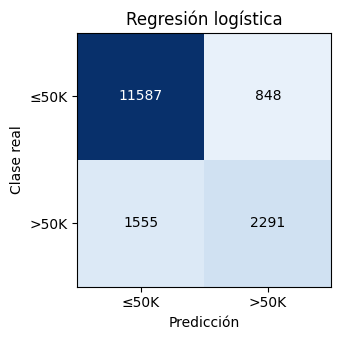

In [34]:
# Se evalúa el modelo y se muestra su matriz de confusión
resultado_rl = medir_modelo(modelo_rl, "Regresión logística")

**Interpretación.** La regresión logística identificó 2.291 casos con ingresos superiores a USD 50.000 y dejó sin detectar 1.555. Su precisión fue del 72,99 % y su sensibilidad del 59,57 %. Sirve como referencia porque su F1 (0,6560) quedó cerca del mayor obtenido en el taller.

### 2. Naive Bayes

Usa los indicadores binarios preparados para estimar la probabilidad de cada clase.

In [35]:
# Se ajusta el modelo con la partición de entrenamiento
nb = NaiveBayes(modelType="bernoulli", featuresCol="features_nb")
modelo_nb = nb.fit(train)

Exactitud: 0.7966
Precisión >50K: 0.5476
Sensibilidad >50K: 0.8006
F1 >50K: 0.6503
ROC AUC: 0.8858
PR AUC: 0.7001


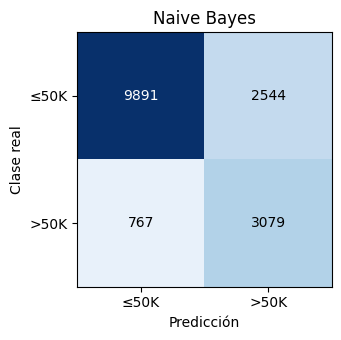

In [36]:
# Se evalúa el modelo y se muestra su matriz de confusión
resultado_nb = medir_modelo(modelo_nb, "Naive Bayes")

**Interpretación.** Naive Bayes detectó 3.079 de los 3.846 casos positivos, la mayor sensibilidad de los cinco modelos (80,06 %). También produjo 2.544 falsos positivos, el mayor número de la comparación, y obtuvo la menor precisión para esta clase (54,76 %).

### 3. Árbol de decisión

Clasifica mediante reglas que pueden combinar distintas variables.

In [37]:
# Se ajusta el modelo con la partición de entrenamiento
arbol = DecisionTreeClassifier(maxDepth=6, seed=SEMILLA)
modelo_arbol = arbol.fit(train)

Exactitud: 0.8418
Precisión >50K: 0.7745
Sensibilidad >50K: 0.4662
F1 >50K: 0.5820
ROC AUC: 0.8754
PR AUC: 0.7363


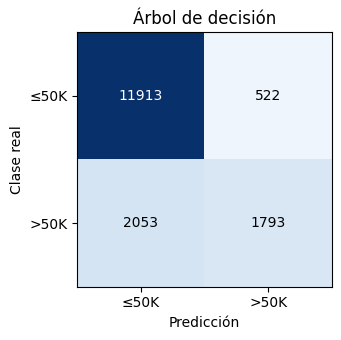

In [38]:
# Se evalúa el modelo y se muestra su matriz de confusión
resultado_arbol = medir_modelo(modelo_arbol, "Árbol de decisión")

**Interpretación.** El árbol de decisión identificó 1.793 casos positivos y dejó sin detectar 2.053. Alcanzó una precisión del 77,45 % y generó 522 falsos positivos. Su sensibilidad (46,62 %) y su F1 (0,5820) fueron los menores de la comparación.

### 4. Random Forest

Combina las predicciones de 60 árboles.

In [39]:
# Se ajusta el modelo con la partición de entrenamiento
rf = RandomForestClassifier(numTrees=60, maxDepth=8, seed=SEMILLA)
modelo_rf = rf.fit(train)

26/11/23 17:21:26 WARN DAGScheduler: Broadcasting large task binary with size 1063.5 KiB
26/11/23 17:21:27 WARN DAGScheduler: Broadcasting large task binary with size 1528.5 KiB
                                                                                

26/11/23 17:21:28 WARN DAGScheduler: Broadcasting large task binary with size 1003.1 KiB
26/11/23 17:21:28 WARN DAGScheduler: Broadcasting large task binary with size 1003.7 KiB


Exactitud: 0.8474
Precisión >50K: 0.8002
Sensibilidad >50K: 0.4717
F1 >50K: 0.5935
ROC AUC: 0.8996
PR AUC: 0.7532


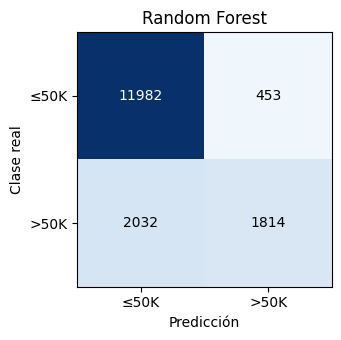

In [40]:
# Se evalúa el modelo y se muestra su matriz de confusión
resultado_rf = medir_modelo(modelo_rf, "Random Forest")

**Interpretación.** Random Forest tuvo la mayor precisión (80,02 %) y el menor número de falsos positivos (453). Detectó 1.814 casos positivos y omitió 2.032. Frente al árbol individual, detectó 21 casos más y produjo 69 falsos positivos menos.

### 5. Perceptrón multicapa

Usa el vector escalado y una capa oculta de 16 unidades.

In [41]:
# Se ajusta el modelo con la partición de entrenamiento
mlp = MultilayerPerceptronClassifier(
    featuresCol="features_mlp", layers=[entradas_mlp, 16, 2],
    maxIter=60, blockSize=128, seed=SEMILLA
)
modelo_mlp = mlp.fit(train)

Exactitud: 0.8538
Precisión >50K: 0.7197
Sensibilidad >50K: 0.6243
F1 >50K: 0.6686
ROC AUC: 0.9048
PR AUC: 0.7658


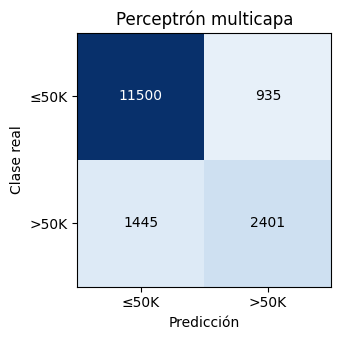

In [42]:
# Se evalúa el modelo y se muestra su matriz de confusión
resultado_mlp = medir_modelo(modelo_mlp, "Perceptrón multicapa")

**Interpretación.** El perceptrón multicapa detectó 2.401 casos con ingresos superiores a USD 50.000 (62,43 % de sensibilidad). Frente a la regresión logística, identificó 110 casos adicionales y produjo 87 falsos positivos más. Su F1 (0,6686) fue el mayor de esta corrida.

## 5. Análisis de resultados

La precisión indica cuántas de las personas clasificadas por encima de USD 50.000 efectivamente superan el umbral. La sensibilidad indica cuántas de las que realmente lo superan fueron detectadas. Usamos F1 para comparar el equilibrio entre las dos medidas.

In [43]:
# Se reúnen las métricas y los conteos de los cinco modelos
resultados = [resultado_rl, resultado_nb, resultado_arbol, resultado_rf, resultado_mlp]
comparacion = pd.DataFrame(resultados).set_index("Modelo")
print(comparacion.round(4).to_string())

                         VN    FP    FN    VP  Exactitud  Precisión >50K  Sensibilidad >50K  F1 >50K  ROC AUC  PR AUC
Modelo                                                                                                               
Regresión logística   11587   848  1555  2291     0.8524          0.7299             0.5957   0.6560   0.9041  0.7608
Naive Bayes            9891  2544   767  3079     0.7966          0.5476             0.8006   0.6503   0.8858  0.7001
Árbol de decisión     11913   522  2053  1793     0.8418          0.7745             0.4662   0.5820   0.8754  0.7363
Random Forest         11982   453  2032  1814     0.8474          0.8002             0.4717   0.5935   0.8996  0.7532
Perceptrón multicapa  11500   935  1445  2401     0.8538          0.7197             0.6243   0.6686   0.9048  0.7658


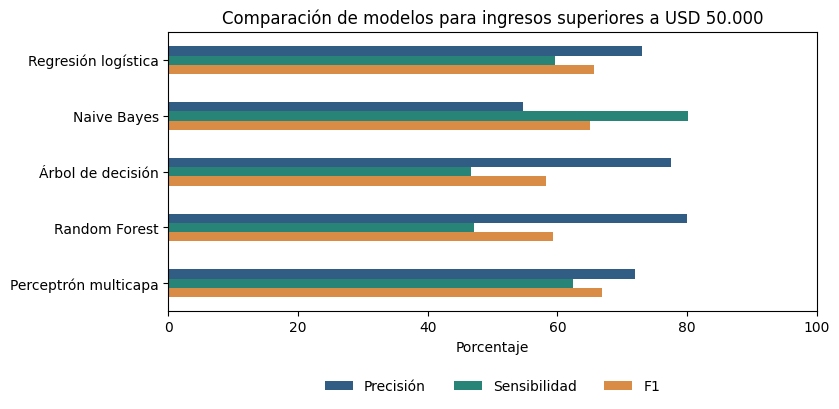

In [44]:
# Se comparan las métricas de la clase positiva en una gráfica
metricas_positivas = ["Precisión >50K", "Sensibilidad >50K", "F1 >50K"]
ax = (comparacion[metricas_positivas].mul(100)
      .plot.barh(figsize=(8.5, 4.3), color=["#315C83", "#288477", "#D88C46"]))
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Porcentaje", ylabel="",
       title="Comparación de modelos para ingresos superiores a USD 50.000")
ax.legend(["Precisión", "Sensibilidad", "F1"], loc="upper center",
          bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.figure.tight_layout()
plt.show()

**Interpretación.** La gráfica muestra tres resultados distintos. Naive Bayes recupera la mayor proporción de casos positivos y Random Forest acierta con mayor frecuencia cuando predice un ingreso superior a USD 50.000. El perceptrón multicapa obtuvo el mayor F1, seguido de cerca por la regresión logística (0,6686 frente a 0,6560).

## 6. Conclusiones y recomendación

En la prueba oficial se recomendaría el perceptrón multicapa si interesa equilibrar la detección de ingresos superiores a USD 50.000 y la precisión de esas predicciones. Identificó 2.401 de los 3.846 casos positivos y obtuvo el mayor F1 (0,6686). La regresión logística quedó cerca (0,6560), de modo que la ventaja observada es pequeña y corresponde a esta partición.

La elección cambia con el costo del error. Naive Bayes detectó 678 casos positivos más que el perceptrón, a cambio de 1.609 falsas alarmas adicionales. Random Forest produjo solo 453 falsas alarmas, aunque dejó sin detectar 2.032 casos positivos. Por eso conviene mirar los conteos de la matriz junto con la exactitud.

Guardar cada etapa en un DataFrame distinto permitió volver a los registros originales y comprobar qué cambió. Por ejemplo, al comparar df01 con df03 se puede seguir un valor faltante desde su registro original hasta la categoría Desconocido. Si solo se revisara el último conteo de nulos, ese detalle se perdería.

Una comparación de modelos también depende de cómo se separan los datos. Aprender las categorías, las escalas y los intervalos con entrenamiento permite evaluar los cinco modelos sobre registros reservados. Si se quisiera ajustar el umbral o los parámetros, se podría usar una parte del entrenamiento para validación y reservar la prueba para la evaluación final.

## Referencias

- Kohavi, R. (1996). [Census Income](https://doi.org/10.24432/C5GP7S). UCI Machine Learning Repository.
- İlhan, Ş. [Classification Models with Pyspark in Bank Dataset](https://www.kaggle.com/code/ilhansevval/classification-models-with-pyspark-in-bank-dataset), guía de preparación y evaluación con Spark.
- Mulye, A. [Adult Income Dataset | From Scratch](https://www.kaggle.com/code/aditimulye/adult-income-dataset-from-scratch), guía de exploración de Adult.

In [45]:
# Se detiene la sesión de Spark al terminar el taller
spark.stop()